<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Spinwave_Dispersion_ATM_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

100%|██████████| 399/399 [00:29<00:00, 13.65it/s]


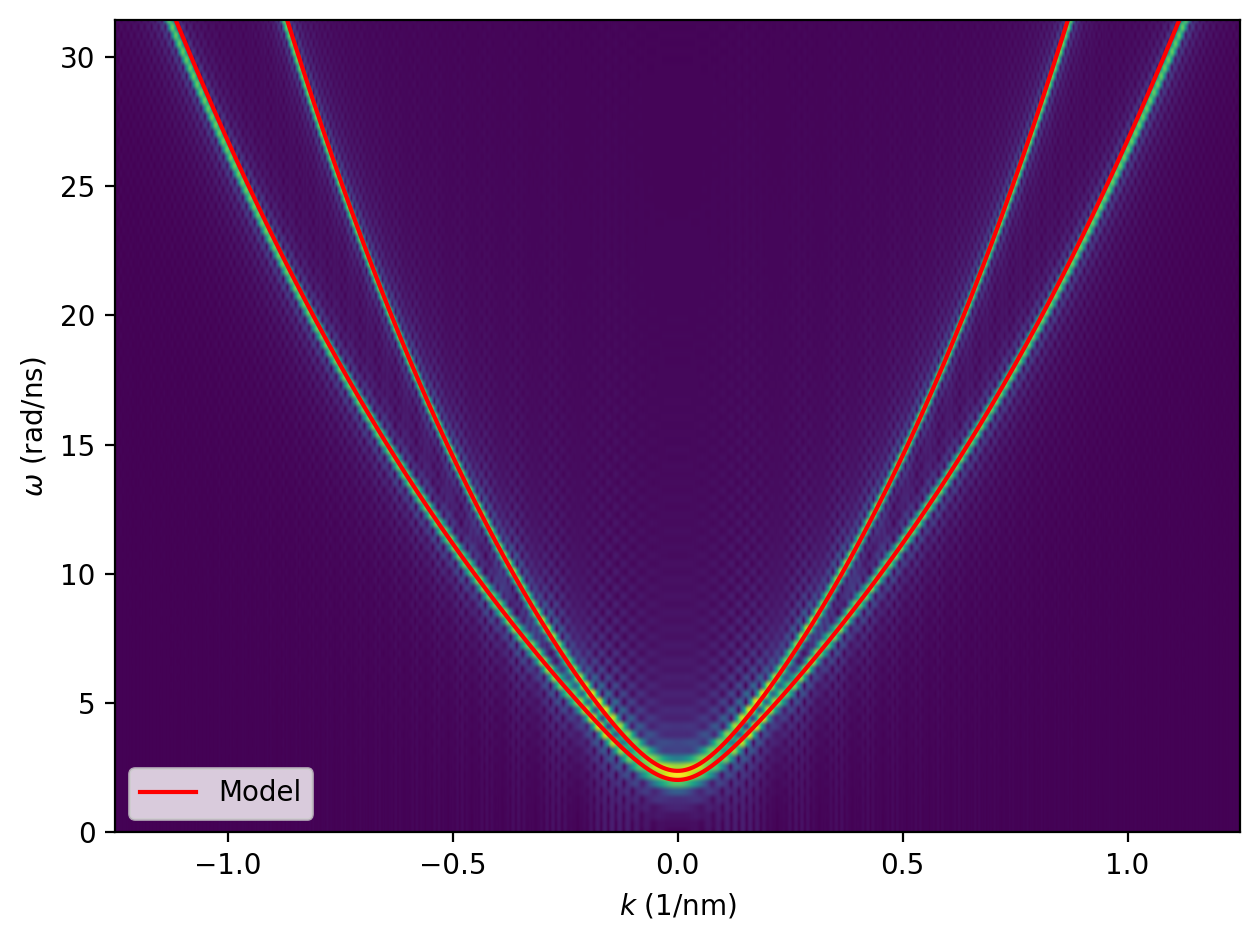

In [3]:
"""This script simulates the dispersion of spinwaves
in a 1D altermagnet as described in https://doi.org/10.1063/5.0341263.
"""
import os.path

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from mumaxplus import Altermagnet, Grid, World
from mumaxplus.util.constants import GAMMALL_DEFAULT

plt.rcParams["figure.dpi"] = 200

# Numerical parameters
fmax = 1E13               # maximum frequency (in Hz) of the sinc pulse
T    = 20E-12             # simulation time (longer -> better frequency resolution)
dt   = 1 / (2 * fmax)     # the sample time
nt   = 1 + int(T / dt)
dx   = 0.5E-9             # cellsize
nx   = 6000               # number of cells

# Material/system parameters
a     = 0.35e-9       # lattice constant
Bz    = 1             # bias field along the z direction
Ms    = 2.9e5         # saturation magnetization
alpha = 1e-3          # damping parameter
K     = 2e5           # uniaxial anisotropy constant

A0  = -5e-13          # homogeneous exchange (AFM)
A12 = A0 / 2          # inhomogeneous exchange (ATM)
A1  = 25e-12          # first exchange matrix eigenvalue
A2  = 15e-12          # second exchange matrix eigenvalue
angle = 0             # angle between exchange matrix eigenbasis and simulation grid


# Create the world
grid_size = (nx, 1, 1)
cell_size = (dx, dx, dx)

m_filename = f"ATM_dispersion_data.npy"

world = World(cell_size)
world.bias_magnetic_field = (0, 0, Bz)

def simulate():
    magnet = Altermagnet(world, Grid(size=grid_size))
    magnet.msat  = Ms
    magnet.alpha = alpha
    magnet.ku1   = K
    magnet.anisU = (0, 0, 1)

    magnet.latcon = a

    magnet.afmex_cell = A0
    magnet.afmex_nn   = A12
    magnet.alterex_1  = A1
    magnet.alterex_2  = A2
    magnet.alterex_angle = angle

    Bt = lambda t: (1e2 * np.sinc(2 * fmax * (t - T / 2)), 0, 0)
    mask = np.zeros(shape=(1, 1, nx))
    # Put signal at the center of the simulation box
    mask[:, :, nx // 2 - 1:nx // 2 + 1] = 1
    for sub in magnet.sublattices:
        sub.bias_magnetic_field.add_time_term(Bt, mask)

    magnet.sub1.magnetization = (0, 0, 1)
    magnet.sub2.magnetization = (0, 0, -1)

    # Run solver
    m1 = np.zeros(shape=(nt, 3, 1, 1, nx))
    m2 = np.zeros(shape=(nt, 3, 1, 1, nx))
    m1[0,...] = magnet.sub1.magnetization.eval()
    m2[0,...] = magnet.sub2.magnetization.eval()
    for i in tqdm(range(nt - 1)):
        world.timesolver.run(dt)
        m1[i + 1,...] = magnet.sub1.magnetization.eval()
        m2[i + 1,...] = magnet.sub2.magnetization.eval()
    np.save(m_filename, np.array([m1, m2]))
    return m1, m2


# check if the files already exist
if os.path.isfile(m_filename):
    m1, m2 = np.load(m_filename)
else:
    m1, m2 = simulate()

# x- and y-coordinates of FT cell centers
ks = np.fft.fftshift(np.fft.fftfreq(nx, dx) * 2*np.pi)
fs = np.fft.fftshift(np.fft.fftfreq(nt, dt))
# FT cell widths
dk = ks[1] - ks[0]
df = fs[1] - fs[0]
# image extent of k-values and frequencies, compensated for cell-width
extent = [ks[0] - dk/2, ks[-1] + dk/2, fs[0] - df/2, fs[-1] + df/2]

# Fourier transform in time and x-direction of magnetization
m1_FT = np.abs(np.fft.fftshift(np.fft.fft2(m1[:,1,0,0,:])))
m2_FT = np.abs(np.fft.fftshift(np.fft.fft2(m2[:,1,0,0,:])))

# extent of k values and frequencies, compensated for cell-width
xmin, xmax = -1.25*1e9, 1.25*1e9  # rad/m
ymin, ymax = 0, fmax  # Hz

# normalize the transform in the relevant area, so it is visible in the plot
x_start = int((xmin - extent[0]) / (extent[1] - extent[0]) * nx)
x_end   = int((xmax - extent[0]) / (extent[1] - extent[0]) * nx)
y_start = int((ymin - extent[2]) / (extent[3] - extent[2]) * nt)
y_end   = int((ymax - extent[2]) / (extent[3] - extent[2]) * nt)

m1_max = np.max(m1_FT[y_start:y_end, x_start:x_end])
m2_max = np.max(m2_FT[y_start:y_end, x_start:x_end])

FT_tot1 = m1_FT/m1_max
FT_tot2 = m2_FT/m2_max

# Sum of sublattice spectra produces the nicest plot
FT_tot = FT_tot1 + FT_tot2

fig, ax = plt.subplots()

# Plot the analytical derived dispersion relation
k  = np.linspace(xmin, xmax, 2500)
kx = k
ky = 0

wext = Bz
wani = 2 * K / Ms
wc   = 4 * A0 / (a*a*Ms)
wnn  = A12 / Ms * k**2

wex  = (A1 + A2) * k**2 / Ms
walt = (A1 - A2) * (np.cos(2*angle) * (kx**2 - ky**2) + 2 * np.sin(2*angle) * kx * ky) / Ms

wmagnon = np.sqrt((wani + wex - wnn) * (wani + wex - 2*wc + wnn))

w1 = GAMMALL_DEFAULT * ( wmagnon + wext + walt)
w2 = GAMMALL_DEFAULT * ( wmagnon - wext - walt)

# plot numerical result
xscale = 1e-9
yscale = 1e-12 * (2*np.pi)
rescaled_extent =  [extent[0] * xscale,
                    extent[1] * xscale,
                    extent[2] * yscale,
                    extent[3] * yscale]
ax.imshow(FT_tot, aspect='auto', origin='lower', extent=rescaled_extent, cmap="viridis")

ax.plot(xscale * k, yscale * w1 / (2 * np.pi), '-', color="red", label="Model")
ax.plot(xscale * k, yscale * w2 / (2 * np.pi), '-', color="red")

ax.set_xlim([xmin * xscale, xmax * xscale])
ax.set_ylim([ymin * yscale, ymax / 2 * yscale])
ax.set_ylabel(r"$\omega$ (rad/ns)")
ax.set_xlabel(r"$k$ (1/nm)")
plt.legend()
plt.tight_layout()
plt.show()